# Hypothesis Testing for EDA: Exercise

You are exploring the `taxis` dataset: 6,433 New York City taxi rides with the distance, fare, tip, payment method, cab colour, and pickup/dropoff location of each ride. As in the EDA guide, every pattern you spot needs a test before it goes in your report.

For each exercise below, follow the same recipe as the guide notebook:

1. **Plot** the pair of variables.
2. **Quantify** the pattern with an effect size (correlation coefficient, difference in means, Cramér's V).
3. **Test** it with the matching hypothesis test.
4. **Interpret** the result in plain language: is the pattern real, and does it matter?

> [!NOTE]
> This dataset is realistically messy: `payment` and the borough columns contain some missing values. Decide how to handle them before testing (dropping the affected rows is fine, state that you did it).

## Learning Objectives

At the end of this notebook, you should be able to:

- Select and run the matching association test for each variable-pair type without a template.
- Check test assumptions on messy real data and switch to a robust alternative when they fail.
- Distinguish statistical significance from practical relevance using effect sizes.
- Spot patterns that a test confirms but a data-recording artifact explains.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

df = sns.load_dataset("taxis")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


---
## Exercise 1: Do Longer Rides Cost More?

Numeric vs numeric: `distance` and `fare`.

- Make the scatter plot.
- Compute the Pearson correlation and its p-value. Compare with Spearman.
- Interpret the coefficient and the p-value together. Is this finding interesting for a stakeholder, or just a sanity check of how taxi meters work?

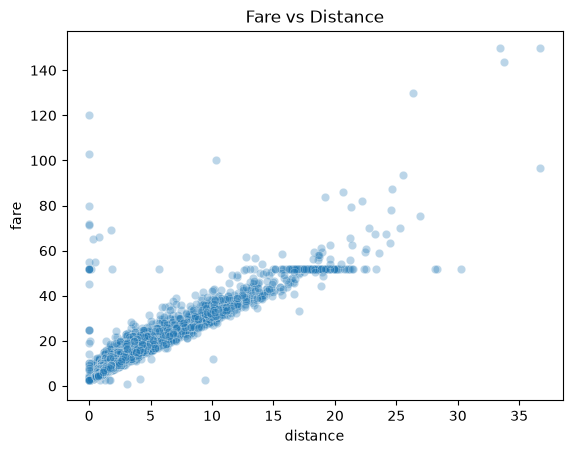

Pearson r:  0.920, p-value: 0.0e+00
Spearman r: 0.926, p-value: 0.0e+00


In [2]:
# Your code here

sns.scatterplot(data=df, x="distance", y="fare", alpha=0.3)
plt.title("Fare vs Distance")
plt.show()

r, p_pearson = stats.pearsonr(df["distance"], df["fare"])
rs, p_spearman = stats.spearmanr(df["distance"], df["fare"])
print(f"Pearson r:  {r:.3f}, p-value: {p_pearson:.1e}")
print(f"Spearman r: {rs:.3f}, p-value: {p_spearman:.1e}")

Your interpretation here:

---
## Exercise 2: Do Card Payers Tip More Than Cash Payers?

Categorical (2 groups) vs numeric: `payment` and `tip`.

- Plot the tip distribution per payment method and compute the group means.
- Run the appropriate two-group test.
- The test will scream "significant". Before you write the conclusion, look at the cash tips themselves. What is really going on, and can any hypothesis test detect it?

> [!TIP]
> A p-value tells you the pattern is not random noise. It cannot tell you the pattern means what you think it means. Look at *how* this dataset records cash tips.

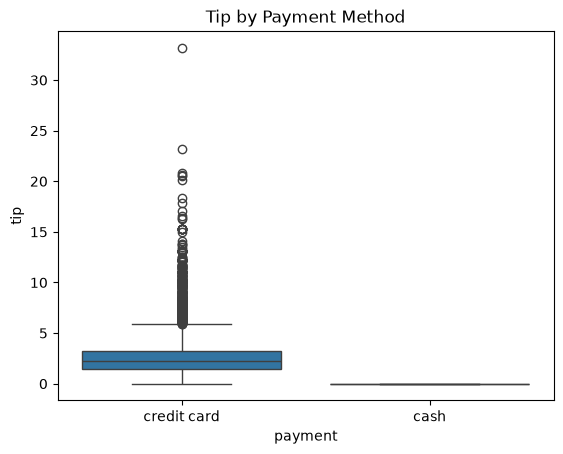

Card: n 4577, mean tip 2.78
Cash: n 1812, mean tip 0.00
Welch t-statistic: 75.6, p-value: 0.0e+00
Share of cash rides with a recorded tip of exactly 0: 1.000


In [3]:
# Your code here
paid = df.dropna(subset=["payment"])
card = paid[paid["payment"] == "credit card"]["tip"]
cash = paid[paid["payment"] == "cash"]["tip"]

sns.boxplot(data=paid, x="payment", y="tip")
plt.title("Tip by Payment Method")
plt.show()

print(f"Card: n {len(card)}, mean tip {card.mean():.2f}")
print(f"Cash: n {len(cash)}, mean tip {cash.mean():.2f}")

t_stat, p_value = stats.ttest_ind(card, cash, equal_var=False)
print(f"Welch t-statistic: {t_stat:.1f}, p-value: {p_value:.1e}")

# The step that saves the analysis: look at the raw cash tips
print(f"Share of cash rides with a recorded tip of exactly 0: {(cash == 0).mean():.3f}")

Your interpretation here:

### Exercise 2b (Trickier): Do Green Cabs Charge Higher Fares?

Same pair type: `color` and `fare`.

- Compare the mean **and** the median fare of yellow and green cabs.
- Run both Welch's t-test and the Mann-Whitney U test.
- The two tests disagree at alpha = 0.05, and the means and medians tell different stories. Explain what is happening and what you would report.

> [!TIP]
> When means differ but medians are identical, ask which part of the distribution is doing the work, and remember the two tests are not asking exactly the same question.

In [4]:
# Your code here
yellow = df[df["color"] == "yellow"]["fare"]
green = df[df["color"] == "green"]["fare"]

print(
    f"Yellow: n {len(yellow)}, mean {yellow.mean():.2f}, median {yellow.median():.2f}"
)
print(f"Green:  n {len(green)}, mean {green.mean():.2f}, median {green.median():.2f}")

t_stat, p_welch = stats.ttest_ind(yellow, green, equal_var=False)
u_stat, p_mw = stats.mannwhitneyu(yellow, green)
print(f"Welch t-test p-value:   {p_welch:.4f}")
print(f"Mann-Whitney U p-value: {p_mw:.4f}")

Yellow: n 5451, mean 12.92, median 9.50
Green:  n 982, mean 14.04, median 9.50
Welch t-test p-value:   0.0102
Mann-Whitney U p-value: 0.0607


Your interpretation here:

---
## Exercise 3: Does the Fare Depend on the Pickup Borough?

Categorical (4 groups) vs numeric: `pickup_borough` and `fare`.

- Plot fare per borough and compute the group means.
- Run the test that compares all four groups at once.
- Interpret the result. What would be the correct follow-up to find out **which** boroughs differ, and what must that follow-up guard against?

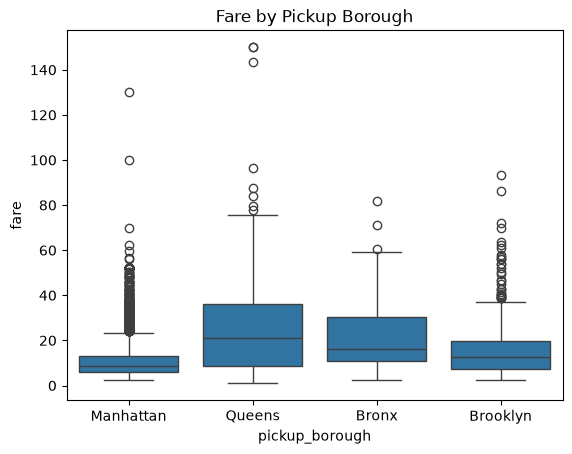

                count   mean
pickup_borough              
Bronx              99  21.00
Brooklyn          383  16.52
Manhattan        5268  11.15
Queens            657  24.93
ANOVA F-statistic: 371.4, p-value: 2.2e-222


In [5]:
# Your code here
boro = df.dropna(subset=["pickup_borough"])

sns.boxplot(data=boro, x="pickup_borough", y="fare")
plt.title("Fare by Pickup Borough")
plt.show()

print(boro.groupby("pickup_borough")["fare"].agg(["count", "mean"]).round(2))

groups = [g["fare"].values for _, g in boro.groupby("pickup_borough")]
f_stat, p_value = stats.f_oneway(*groups)
print(f"ANOVA F-statistic: {f_stat:.1f}, p-value: {p_value:.1e}")

Your interpretation here:

---
## Exercise 4: Do Yellow and Green Cabs Work Different Boroughs?

Categorical vs categorical: `color` and `pickup_borough`.

- Make the count plot and build the contingency table.
- Run the chi-square test of independence and compute Cramér's V.
- Interpret both numbers. Then repeat for `payment` vs `color` and compare the two effect sizes: which association is strong and which is significant-but-weak?

> [!TIP]
> New York licenses green cabs specifically for the boroughs outside the Manhattan core. Does the data show it?

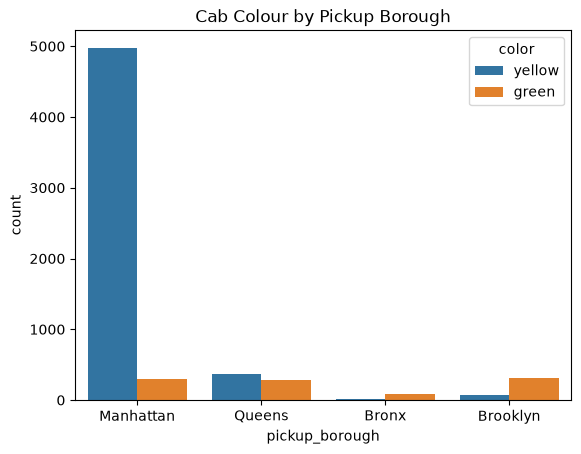

pickup_borough  Bronx  Brooklyn  Manhattan  Queens
color                                             
green              83       313        294     288
yellow             16        70       4974     369
Chi-square: 2464.3, p-value: 0.0e+00, dof: 3, Cramér's V: 0.620
payment vs color: chi-square 89.1, p-value 3.7e-21, Cramér's V: 0.118


In [6]:
# Your code here
def cramers_v(table):
    chi2, _, _, _ = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


sns.countplot(data=boro, x="pickup_borough", hue="color")
plt.title("Cab Colour by Pickup Borough")
plt.show()

table_color = pd.crosstab(boro["color"], boro["pickup_borough"])
print(table_color)
chi2, p_value, dof, _ = stats.chi2_contingency(table_color)
print(
    f"Chi-square: {chi2:.1f}, p-value: {p_value:.1e}, dof: {dof}, Cramér's V: {cramers_v(table_color):.3f}"
)

# Second pair: payment vs colour
table_pay = pd.crosstab(paid["payment"], paid["color"])
chi2b, p_b, _, _ = stats.chi2_contingency(table_pay)
print(
    f"payment vs color: chi-square {chi2b:.1f}, p-value {p_b:.1e}, Cramér's V: {cramers_v(table_pay):.3f}"
)

Your interpretation here:

---
## Exercise 5: Reflection, the Multiple-Testing Ledger

No code needed. Count the tests you ran in this notebook (including assumption checks), then answer:

1. At alpha = 0.05, roughly how worried should you be about false positives across that many tests?
2. Which of your findings would you report as solid, which as leads needing confirmation, and which as artifacts of how the data was recorded? Justify each with the p-value **and** the effect size.

Your answers here:

- **Solid**: fare vs distance (r = 0.92, p about 0), fare by borough (p about 2e-222), colour by borough (p about 0, V = 0.62). All three survive any correction and carry large effect sizes.
- **Lead needing confirmation**: yellow vs green fares. Welch p = 0.010 does not survive Bonferroni, Mann-Whitney disagrees, and the medians are identical: report as a tail-behaviour hypothesis, not a conclusion.
- **Artifact**: card vs cash tips. The p-value is as small as they come, and the finding is still wrong as a behavioural claim, because cash tips are simply not recorded. No correction fixes a measurement problem.
- **Significant but weak**: payment vs colour (V = 0.12). Real, but too small to matter for most decisions; report the effect size alongside the p-value.

---
## Summary

In this notebook you:

- Selected and ran the matching test for four variable-pair questions on messy real data.
- Checked assumptions and switched to robust alternatives where normality failed.
- Separated statistical significance from practical relevance using effect sizes.
- Caught a pattern that the test confirms but a data-recording artifact explains.

Compare your approach with the worked reference in the `solutions/` folder once you have finished, not before.

## References & Further Reading

- [**scipy.stats reference**](https://docs.scipy.org/doc/scipy/reference/stats.html): Every test you need for these exercises.
- [**scipy.stats.chi2_contingency**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html): Chi-square test of independence.
- [**Codecademy: Testing an Association cheat sheet**](https://www.codecademy.com/learn/hypothesis-testing-python/modules/hp-testing-an-association/cheatsheet): One-page recap of which test fits which pair.
- [**StatQuest: P-hacking**](https://www.youtube.com/watch?v=HDCOUXE3HMM): Watch before writing your Exercise 5 answers.